### This notebook contains code to recreate analyses of behaviour in the lesion patient cohort 

Uses maps outputted from the voxelwise lesion analysis  and fMRI analyses 
Code from Figure 5c,d and Supplementary fig.9a,b,e


Eleanor Holton, 19/01/2024

In [2]:
import matplotlib as mpl
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import scipy.stats as stats
import glob

# Import packages for working with fmri files
import nilearn
from nilearn import image
from nilearn import plotting
import nibabel as nib

# set base folder to import functions
base_folder = '/Users/eleanorholton/Dropbox/nature_human_behaviour/goal_pursuit_final/'
data_folder = base_folder + 'data/lesion_patient_study/'
plot_folder = ''
mapFolder = '/Users/eleanorholton/Dropbox/Oxford/PhD/Nils/goalmaintenance/patient_project/individual_lesion_maps/' # lesion maps not stored publicly with data to protect privacy 

# load behavioural functions from fmri behavioural processing scripts
import sys
import os
sys.path.append(os.path.abspath(base_folder + "scripts/mri_study/behaviour/"))
import behav_functions as bf

# Plotting settings
quartiles_colours = sns.color_palette("Purples")[:][2:6] 
model_colours = ["#D3D3D3","#D3D3D3", "#D3D3D3", quartiles_colours[3],"#000000"]#, "#FFC20A"]
  
small_label_fontsize = 15
medium_label_fontsize = 18


#### Plot glass-brain map of all lesions

In [3]:
# plot lesion map
aggregate_maps = image.smooth_img(data_folder + 'lesion_maps/lesions_combined_map.nii.gz',fwhm = 1)
glass_brain_output = data_folder + 'glass_brain_patients.png'
cmap = mpl.cm.spring 
display = plotting.plot_glass_brain(aggregate_maps,vmin=0,vmax=10,cmap=cmap, cbar_tick_format="%i",colorbar=True,output_file=glass_brain_output)

ValueError: File not found: '/Users/eleanorholton/Dropbox/nature_human_behaviour/goal_pursuit_final/data/lesion_patient_study/lesion_maps/lesions_combined_map.nii.gz'

#### Import behav data 

In [4]:
# Import fmri cluster (for independent analysis of vmpfc damage on persistence)
fmri_peak_file = base_folder + 'data/mri_study/neural/ROI/inter_decision_goal_tracking_peak/inter_decision_goal_tracking_peak_sphere.nii.gz'
fmri_peak = nib.load(fmri_peak_file)
fmri_peak = fmri_peak.get_fdata()
fmri_peak[fmri_peak>0]=1 # binarize the mask

# Import cluster from voxel_wise_regression (for post-hoc performance tests)
voxelwise_analysis_cluster_file = base_folder + 'data/lesion_patient_study/voxelwise_regression/cluster_corrected_tstats.nii.gz'
voxelwise_analysis_cluster = nib.load(voxelwise_analysis_cluster_file)
voxelwise_analysis_cluster = voxelwise_analysis_cluster.get_fdata()
voxelwise_analysis_cluster[voxelwise_analysis_cluster>0]=1 # binarize the mask

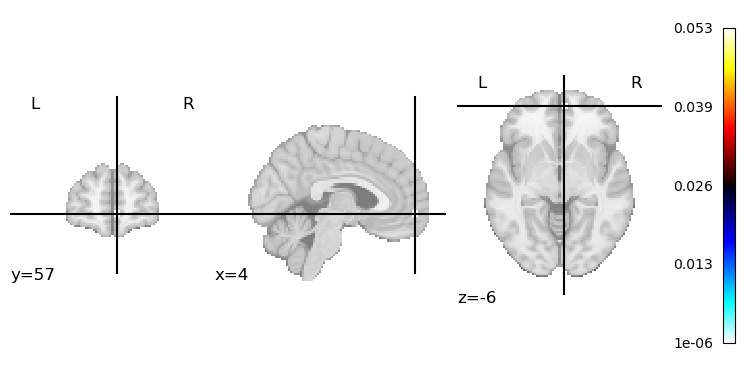

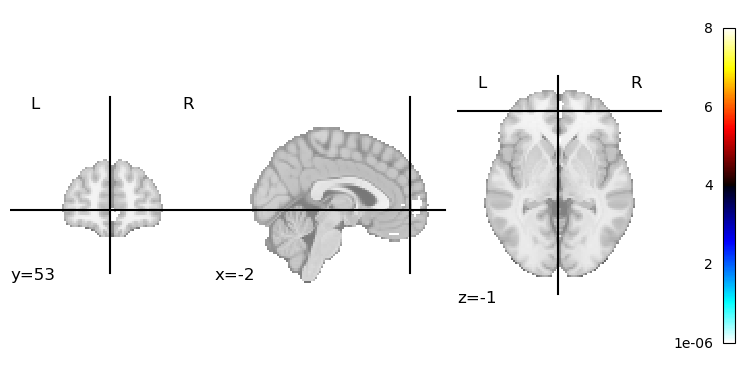

In [5]:
plotting.plot_stat_map(fmri_peak_file)
plotting.plot_stat_map(voxelwise_analysis_cluster_file)

In [7]:
# Import data

patients =  np.array([303, 304, 305, 306, 310, 315, 317, 319, 325, 327, 330, 333, 339, 344, 545, 345, 346, 347, 348, 349, 350, 352, 407]); 

patient_data = pd.DataFrame()


for idx,id in enumerate(patients):
    
    # load data 
    x = pd.read_csv(data_folder  + 'behaviour/all_patient_data/' + str(id) + '.csv') 
    
    # load map
    i_map = nib.load(mapFolder + 'sub_' + str(id) + '.nii.gz')
    i_map_array = i_map.get_fdata()
    
    # Are they damaged in the fMRI cluster? 
    if (np.sum(i_map_array*fmri_peak))>0:
        print('patient ' + str(id) + ' damaged in fmri vmpfc cluster')
        x['fmri_cluster']=1                  
    else:
        x['fmri_cluster']=0 
        
        
    # Are they damaged in the region identified by voxel-wise regression? 
    if (np.sum(i_map_array*voxelwise_analysis_cluster))>0:
        print('vmpfc lesion found in patient ' + str(id) + ' damaged in voxelwise cluster')
        x['voxelwise_cluster']=1                  
    else:
        x['voxelwise_cluster']=0 
                     
    patient_data = pd.concat([patient_data, x])

    del x 
    del i_map
    del i_map_array
    

## Import elderly control data 

EC_data = pd.DataFrame()
elderlyControlDataPath = data_folder + 'behaviour/age_matched_controls/'
for file in glob.glob(elderlyControlDataPath + "*.csv"):
    x = pd.read_csv(file) 
    EC_data = pd.concat([EC_data, x])

# add columns to concatenate data frames
EC_data['fmri_cluster']=0 
EC_data['voxelwise_cluster']=0
EC_data['age_matched_control'] = 1
 
patient_data['age_matched_control'] = 0

patient_data = patient_data.reset_index()
EC_data = EC_data.reset_index()

all_data = pd.concat([patient_data, EC_data]).reset_index()

  

vmpfc lesion found in patient 304 damaged in voxelwise cluster
patient 306 damaged in fmri vmpfc cluster
vmpfc lesion found in patient 306 damaged in voxelwise cluster
patient 317 damaged in fmri vmpfc cluster
vmpfc lesion found in patient 317 damaged in voxelwise cluster
patient 319 damaged in fmri vmpfc cluster
vmpfc lesion found in patient 319 damaged in voxelwise cluster
patient 330 damaged in fmri vmpfc cluster
vmpfc lesion found in patient 330 damaged in voxelwise cluster


In [8]:
## Additional functions

def compute_performance(df):
    
    # Performance = average trials to complete net 
    
    # get participant data 
    participants = df['participant'].unique()
    targets_filled = np.empty((len(participants)))
    trials_per_target = np.empty((len(participants)))
    
    for idx,p in enumerate(participants): 
        pdata = df.loc[df['participant']==p,:]

        # calculate goals completed 
        final_choice = 'val_itm' + str(pdata['choice'].iloc[-1])
        if (pdata[final_choice].iloc[-1]+pdata['net_contents'].iloc[-1]) > pdata['goal_size'].iloc[-1]:
            targets_filled[idx] = pdata['block'].max()
        else:
            targets_filled[idx] = pdata['block'].max()-1

        # calculate average trials per block 
        
        trials_per_target[idx] = pdata.loc[pdata['block']<=(targets_filled[idx]),'total_trial_number'].max() / targets_filled[idx] # take number of targets filled divided by number of trials to last completed target (excluding unfinished final target)
        df.loc[df['participant']==p,'performance']=trials_per_target[idx]
        
    return df, targets_filled, trials_per_target 
    
def compute_biases(df):
    
    # Compute persistence bias, i.e. the 'indifference point' to switching (in terms of sampler value)
    
    participants = df['participant'].unique()
    
    bias_const = []
    sampler_betas = []
    indifference_points = []
    
    df['persistence_bias']=np.nan
    
    for p in participants: 
        
        # fit indifference point 
        IP, BC, SB = bf.find_indifference_point(df,p)
        
        bias_const.append(BC)
        sampler_betas.append(SB)
        indifference_points.append(IP)
        df.loc[df['participant']==p,'persistence_bias']=IP
        
    return df, indifference_points, bias_const, sampler_betas
        
def plot_patient_variable(ax,vmpfc_variable,other_patient_variable,EC_variable,ylabel,fontsize,vmpfc_label):

    (_, caps, _) = ax.errorbar([0,1,2],[np.mean(vmpfc_variable), np.mean(other_patient_variable),np.mean(EC_variable)],[np.std(vmpfc_variable)/np.sqrt(len(vmpfc_variable)), np.std(other_patient_variable)/np.sqrt(len(other_patient_variable)),np.std(EC_variable)/np.sqrt(len(EC_variable))],capsize=3,linewidth=2,linestyle='None',color='k');
    for cap in caps:
        cap.set_markeredgewidth(2)
    
    # scatter individual points (with jitter)
    ax.scatter(np.tile(0,len(vmpfc_variable))+0.2*(np.random.rand(len(vmpfc_variable))-0.5), vmpfc_variable,alpha=0.3,color='g')
    ax.scatter(np.tile(1,len(other_patient_variable))+0.2*(np.random.rand(len(other_patient_variable))-0.5), other_patient_variable,alpha=0.3,color='g')
    ax.scatter(np.tile(2,len(EC_variable))+0.2*(np.random.rand(len(EC_variable))-0.5), EC_variable,alpha=0.3,color='g')
    
    ax.set_xticks([0,1,2],[vmpfc_label,'other lesion','age-matched controls'],rotation=45,ha='right',fontsize=fontsize)
    ax.set_ylabel(ylabel,fontsize=fontsize)
    
    ax.set_xlim([-0.2,2.2])
    


#### Do patients damaged at fMRI goal tracking peak have lower persistence bias? 

/var/folders/zj/ffnkjqx56vq3n_q05scbqwrc0000gn/T/ipykernel_66907/3271418126.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['persistence_bias']=np.nan
/var/folders/zj/ffnkjqx56vq3n_q05scbqwrc0000gn/T/ipykernel_66907/3271418126.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['persistence_bias']=np.nan
/var/folders/zj/ffnkjqx56vq3n_q05scbqwrc0000gn/T/ipykernel_66907/3271418126.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_

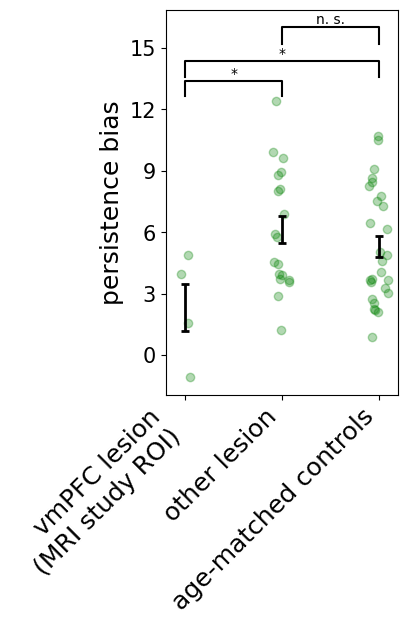

In [9]:
fmri_damaged_dat = all_data.loc[all_data['fmri_cluster']==1,:]
control_lesion_dat =  all_data.loc[(all_data['fmri_cluster']==0)&(all_data['age_matched_control']==0),:]
age_matched_dat =  all_data.loc[all_data['age_matched_control']==1,:]


# compute biases and performance
fmri_damaged_dat, fmri_damaged_bias, _,_ = compute_biases(fmri_damaged_dat)
control_lesion_dat, control_lesion_bias, _,_ = compute_biases(control_lesion_dat)
age_matched_dat,age_matched_bias, _,_= compute_biases(age_matched_dat)

# Plot persistence
ylabel1='persistence bias'
savefig=1
plot_location = plot_folder+'patient_persistence.png'
fig,ax=plt.subplots(figsize=[3,5]); 
vmpfc_label = 'vmPFC lesion\n(MRI study ROI)'
plot_patient_variable(ax,fmri_damaged_bias,control_lesion_bias,age_matched_bias,ylabel1,medium_label_fontsize,vmpfc_label)

# permutation test 
def statistic(x, y):
    return np.mean(x) - np.mean(y)

bf.barplot_annotate_brackets(0, 1, stats.permutation_test((fmri_damaged_bias,control_lesion_bias), statistic,alternative='less').pvalue, [0,1,2],[np.mean(fmri_damaged_bias)+5.8,np.mean(control_lesion_bias)+5.8,np.mean(age_matched_bias)+5.8])
bf.barplot_annotate_brackets(0, 2, stats.permutation_test((fmri_damaged_bias,age_matched_bias), statistic,alternative='less').pvalue, [0,1,2],[np.mean(fmri_damaged_bias)+7.5,np.mean(control_lesion_bias)+7.5,np.mean(age_matched_bias)+7.5])
bf.barplot_annotate_brackets(1, 2, stats.permutation_test((control_lesion_bias,age_matched_bias), statistic,alternative='less').pvalue, [0,1,2],[np.mean(fmri_damaged_bias)+8.2,np.mean(control_lesion_bias)+8.2,np.mean(age_matched_bias)+8.2])

ax.set_yticks(np.arange(0,16,3),np.arange(0,16,3),fontsize=small_label_fontsize)

if savefig:
    fig.savefig(plot_location,bbox_inches='tight',dpi=300)

### Post-hoc analyses of performance and behaviour in the groups identified by the voxel-wise analysis

In [6]:
vmpfc_dat = all_data.loc[all_data['voxelwise_cluster']==1,:]
other_patient_dat =  all_data.loc[(all_data['voxelwise_cluster']==0)&(all_data['age_matched_control']==0),:]
EC_data =  all_data.loc[all_data['age_matched_control']==1,:]


#### Check tree-search model describes behavior best in each group

In [7]:
# set up rpy2 and packages to call mixed effects models (lme4)

%load_ext rpy2.ipython
import rpy2.robjects as ro
from rpy2.robjects.packages import importr

from rpy2.robjects import IntVector, FloatVector, FactorVector, globalenv
lme4 = importr('lme4')
lmerTest = importr('lmerTest')
base = importr('base')
R_stats = importr('stats')
#broom = importr('broom')
utils = importr('utils')

from rpy2.robjects import pandas2ri
pandas2ri.activate()
from rpy2.robjects.conversion import localconverter

ModuleNotFoundError: No module named 'rpy2'

In [52]:
%%R -i vmpfc_dat,other_patient_dat,EC_data -o vmpfc0,vmpfc1,vmpfc2,vmpfc3,modelComparison_vmpfc,other_patient0,other_patient1,other_patient2,other_patient3,modelComparison_other_patient,EC0,EC1,EC2,EC3,modelComparison_EC

library(lme4)
library(lmerTest)

# vmpfc
vmpfc0<-glmer('switch_trial ~ offer_max_value + (1 + offer_max_value|participant)',family=binomial, data=vmpfc_dat)
vmpfc1<-glmer('switch_trial ~ myopic_switch_value + (1 + myopic_switch_value|participant)',family=binomial, data=vmpfc_dat)
vmpfc2<-glmer('switch_trial ~ prosp_switch_value_3+ (1 + prosp_switch_value_3|participant)',family=binomial, data=vmpfc_dat)
vmpfc3<-glmer('switch_trial ~ sampler_switch_value + (1 + sampler_switch_value |participant)',family=binomial, data=vmpfc_dat)

modelComparison_vmpfc <- BIC(vmpfc0,vmpfc1,vmpfc2,vmpfc3)

# other patients
other_patient0<-glmer('switch_trial ~ offer_max_value + (1 + offer_max_value|participant)',family=binomial, data=other_patient_dat)
other_patient1<-glmer('switch_trial ~ myopic_switch_value + (1 + myopic_switch_value|participant)',family=binomial, data=other_patient_dat)
other_patient2<-glmer('switch_trial ~ prosp_switch_value_3+ (1 + prosp_switch_value_3|participant)',family=binomial, data=other_patient_dat)
other_patient3<-glmer('switch_trial ~ sampler_switch_value + (1 + sampler_switch_value |participant)',family=binomial, data=other_patient_dat)

modelComparison_other_patient <- BIC(other_patient0,other_patient1,other_patient2,other_patient3)

# elderly controls
EC0<-glmer('switch_trial ~ offer_max_value + (1 + offer_max_value|participant)',family=binomial, data=EC_data)
EC1<-glmer('switch_trial ~ myopic_switch_value + (1 + myopic_switch_value|participant)',family=binomial, data=EC_data)
EC2<-glmer('switch_trial ~ prosp_switch_value_3+ (1 + prosp_switch_value_3|participant)',family=binomial, data=EC_data)
EC3<-glmer('switch_trial ~ sampler_switch_value + (1 + sampler_switch_value |participant)',family=binomial, data=EC_data)

modelComparison_EC <- BIC(EC0,EC1,EC2,EC3)

R[write to console]: boundary (singular) fit: see help('isSingular')

R[write to console]: boundary (singular) fit: see help('isSingular')



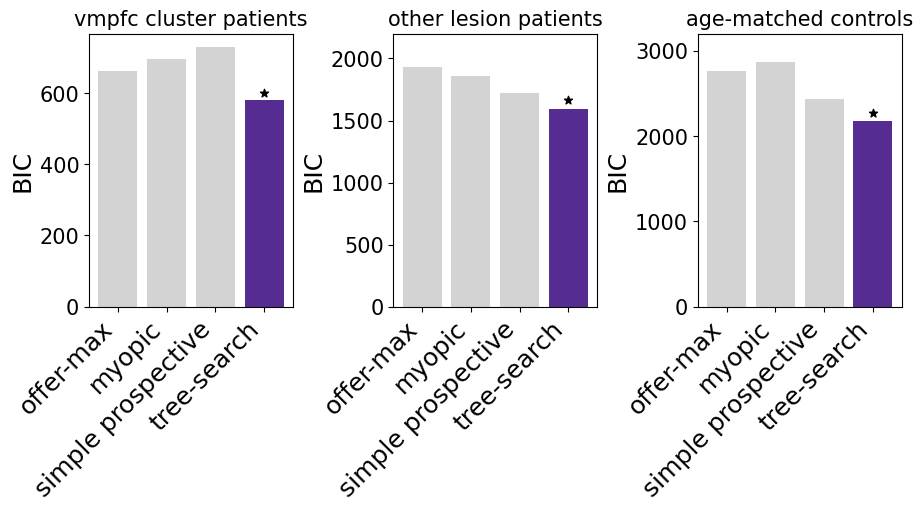

In [55]:
# Plot model comparisons

fig,ax = plt.subplots(1,3,figsize=[9,5], layout="constrained")
modelNames = ['offer-max','myopic','simple prospective','tree-search']
model_labs = modelNames

# ax.set_ylim([4000,6200])
ax[0].bar(np.arange(len(modelComparison_vmpfc)),modelComparison_vmpfc.BIC,color=model_colours[0:6])
ax[0].set_xticks(np.arange(len(modelComparison_vmpfc)), model_labs,fontsize=medium_label_fontsize,rotation=45, ha='right')
ax[0].set_yticks(np.arange(0,601,200),np.arange(0,601,200),fontsize=small_label_fontsize)
#ax[0].set_ylim(0,700)
ax[0].set_ylabel('BIC',fontsize=medium_label_fontsize)
ax[0].scatter(np.argmin(modelComparison_vmpfc.BIC),np.min(modelComparison_vmpfc.BIC)+20,marker='*',color='black')
ax[0].set_title('vmpfc cluster patients',fontsize=small_label_fontsize)

ax[1].bar(np.arange(len(modelComparison_other_patient)),modelComparison_other_patient.BIC,color=model_colours[0:6])
ax[1].set_xticks(np.arange(len(modelComparison_other_patient)), model_labs,fontsize=medium_label_fontsize,rotation=45, ha='right')
ax[1].set_yticks(np.arange(0,2001,500),np.arange(0,2001,500),fontsize=small_label_fontsize)
ax[1].set_ylim([0,2200])
ax[1].set_ylabel('BIC',fontsize=medium_label_fontsize)
ax[1].scatter(np.argmin(modelComparison_other_patient.BIC),np.min(modelComparison_other_patient.BIC)+70,marker='*',color='black')
ax[1].set_title('other lesion patients',fontsize=small_label_fontsize)

ax[2].bar(np.arange(len(modelComparison_EC)),modelComparison_EC.BIC,color=model_colours[0:6])
ax[2].set_xticks(np.arange(len(modelComparison_EC)), model_labs,fontsize=medium_label_fontsize,rotation=45, ha='right')
ax[2].set_ylim([0,3200])
ax[2].set_yticks(np.arange(0,3001,1000),np.arange(0,3001,1000),fontsize=small_label_fontsize)
ax[2].set_ylabel('BIC',fontsize=medium_label_fontsize)
ax[2].scatter(np.argmin(modelComparison_EC.BIC),np.min(modelComparison_EC.BIC)+100,marker='*',color='black')
ax[2].set_title('age-matched controls',fontsize=small_label_fontsize)

fig.savefig(plot_folder+'patient_model_comparison.png',bbox_inches='tight',dpi=300)

#### Compare performance between groups

In [17]:
vmpfc_dat, vmpfc_targets, vmpfc_completion_time= compute_performance(vmpfc_dat)
other_patient_dat, other_patient_targets, other_patient_completion_time = compute_performance(other_patient_dat)
EC_data, EC_targets, EC_completion_time = compute_performance(EC_data)

vmpfc_dat, vmpfc_bias,vmpfc_intercept,vmpfc_beta = compute_biases(vmpfc_dat)
other_patient_dat, other_patient_bias,other_patient_intercept,other_patient_beta  = compute_biases(other_patient_dat)
EC_data,EC_bias,EC_intercept,EC_beta = compute_biases(EC_data)



/var/folders/zj/ffnkjqx56vq3n_q05scbqwrc0000gn/T/ipykernel_66907/3271418126.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[df['participant']==p,'performance']=trials_per_target[idx]
/var/folders/zj/ffnkjqx56vq3n_q05scbqwrc0000gn/T/ipykernel_66907/3271418126.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[df['participant']==p,'performance']=trials_per_target[idx]
/var/folders/zj/ffnkjqx56vq3n_q05scbqwrc0000gn/T/ipykernel_66907/3271418126.py:25: SettingWithCopyWarning: 
A value is try

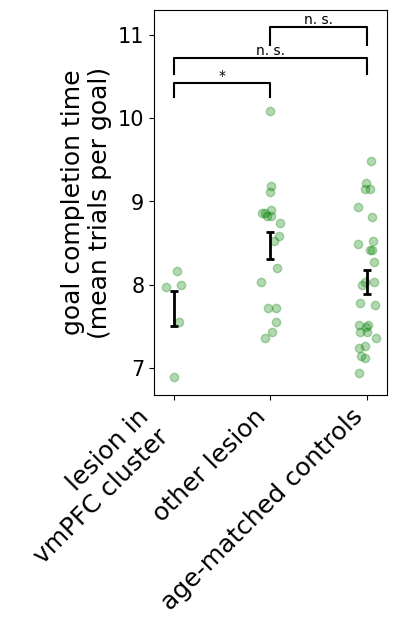

In [16]:
ylabel='goal completion time\n(mean trials per goal)'
savefig=1
fig,ax=plt.subplots(figsize=[3,5]); 
vmpfc_label = 'lesion in\nvmPFC cluster'
plot_patient_variable(ax,vmpfc_completion_time,other_patient_completion_time,EC_completion_time,ylabel,medium_label_fontsize,vmpfc_label)

# permutation test 
def statistic(x, y):
    return np.mean(x) - np.mean(y)

bf.barplot_annotate_brackets(0, 1, stats.permutation_test((vmpfc_completion_time,other_patient_completion_time), statistic).pvalue, [0,1,2],[np.mean(vmpfc_completion_time)+1.6,np.mean(other_patient_completion_time)+1.6,np.mean(EC_completion_time)+1.6])
bf.barplot_annotate_brackets(0, 2, stats.permutation_test((vmpfc_completion_time,EC_completion_time), statistic).pvalue, [0,1,2],[np.mean(vmpfc_completion_time)+2.3,np.mean(other_patient_completion_time)+2.3,np.mean(EC_completion_time)+2.3])
bf.barplot_annotate_brackets(1, 2, stats.permutation_test((other_patient_completion_time,EC_completion_time), statistic).pvalue, [0,1,2],[np.mean(vmpfc_completion_time)+2.2,np.mean(other_patient_completion_time)+2.2,np.mean(EC_completion_time)+2.2])

ax.set_xlim([-0.2,2.2])
ax.set_yticks(np.arange(7,12,1),np.arange(7,12,1),fontsize=small_label_fontsize)


plot_location = plot_folder+'posthoc_performance.png'
if savefig:
    fig.savefig(plot_location,bbox_inches='tight',dpi=300)
    

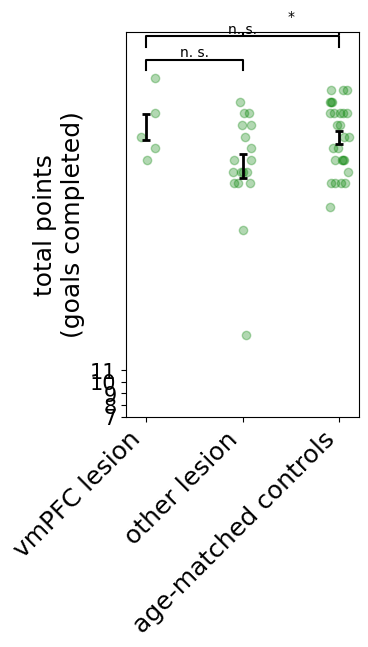

In [18]:
ylabel='total points\n(goals completed)'
savefig=1
fig,ax=plt.subplots(figsize=[3,5]); 
ax.set_ylim([22,40])
vmpfc_label = 'vmPFC lesion'
plot_patient_variable(ax,vmpfc_targets,other_patient_targets,EC_targets,ylabel,medium_label_fontsize,vmpfc_label)

# permutation test 
def statistic(x, y):
    return np.mean(x) - np.mean(y)

bf.barplot_annotate_brackets(0, 1, stats.permutation_test((vmpfc_targets,other_patient_targets), statistic).pvalue, [0,1,2],[np.mean(vmpfc_targets)+4,np.mean(other_patient_targets)+4,np.mean(EC_targets)+4])
bf.barplot_annotate_brackets(0, 2, stats.permutation_test((vmpfc_targets,EC_targets), statistic).pvalue, [0,1,2],[np.mean(vmpfc_targets)+6,np.mean(other_patient_targets)+6,np.mean(EC_targets)+6])
bf.barplot_annotate_brackets(1, 2, stats.permutation_test((other_patient_targets,EC_targets), statistic).pvalue, [0,1,2],[np.mean(vmpfc_targets)+8,np.mean(other_patient_targets)+8,np.mean(EC_targets)+8])

ax.set_xlim([-0.2,2.2])
ax.set_yticks(np.arange(7,12,1),np.arange(7,12,1),fontsize=small_label_fontsize)


plot_location = plot_folder+'posthoc_performance_nets.png'
if savefig:
    fig.savefig(plot_location,bbox_inches='tight',dpi=300)
    

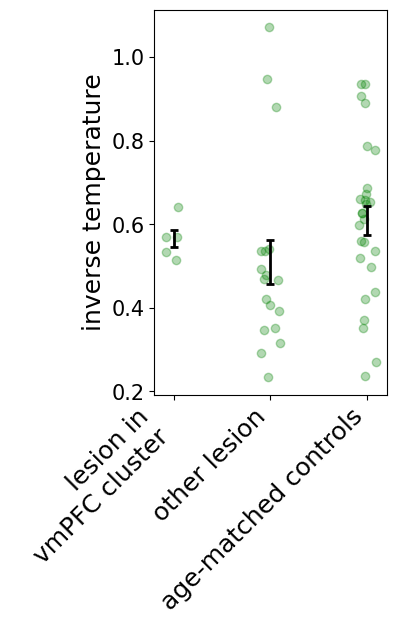

In [11]:
ylabel='inverse temperature'
savefig=1
fig,ax=plt.subplots(figsize=[3,5]); 
vmpfc_label = 'lesion in\nvmPFC cluster'
plot_patient_variable(ax,vmpfc_beta,other_patient_beta,EC_beta,ylabel,medium_label_fontsize,vmpfc_label)

# permutation test 
def statistic(x, y):
    return np.mean(x) - np.mean(y)

ax.set_xlim([-0.2,2.2])
ax.set_yticks(np.arange(0.2,1.1,0.2),np.array([0.2,0.4,0.6,0.8,1.0]),fontsize=small_label_fontsize)


plot_location = plot_folder+'posthoc_temperature.png'
if savefig:
    fig.savefig(plot_location,bbox_inches='tight',dpi=300)

#### Spatial task 

In [12]:
# Import healthy MRI data for comparison
post_scanner_data_folder = base_folder +  'data/mri_study/behaviour/processed/post_scan_session/'

participants = list(range(21,22)) + list(range(23, 43)) + list(range(44, 53)) 
nParticipants = len(participants)

# Import post-scanner data frame
joined_files_postScanner = os.path.join(post_scanner_data_folder, "post_scan_sub_*.csv") # Specify data files
joined_list_postScanner = glob.glob(joined_files_postScanner) # Return list of all data files
df_postScanner = pd.concat(map(pd.read_csv, joined_list_postScanner), ignore_index=True) # import data

In [13]:
# sort spatial error
all_data['sampler_switch_value'] = all_data['sampler_best_alt'] - all_data['sampler_goal_item']
df_postScanner['sampler_switch_value'] = df_postScanner['sampler_best_alt'] - df_postScanner['sampler_goal_item']
    
all_data = bf.categorise_previous_trial(all_data)
df_postScanner = bf.categorise_previous_trial(df_postScanner)

all_data = bf.add_spatial_contrasts(all_data, demeaned=0)
df_postScanner = bf.add_spatial_contrasts(df_postScanner, demeaned=0)

/Users/eleanorholton/Dropbox/nature_human_behaviour/goal_pursuit/scripts/mri_study/behaviour/behav_functions.py:56: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df.iloc[index+1, df.columns.get_loc('prevChoice_mag')] = row[df.choice[index]-1] # index from magnitudes
/Users/eleanorholton/Dropbox/nature_human_behaviour/goal_pursuit/scripts/mri_study/behaviour/behav_functions.py:59: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  row[df.choice[index]-1] = np.nan # set previous choice to nan, to max over alternatives
/Users/eleanorholton/Dropbox/nature_human_behaviour/goal_pursuit/scripts/mri_study/behaviour/behav_fun

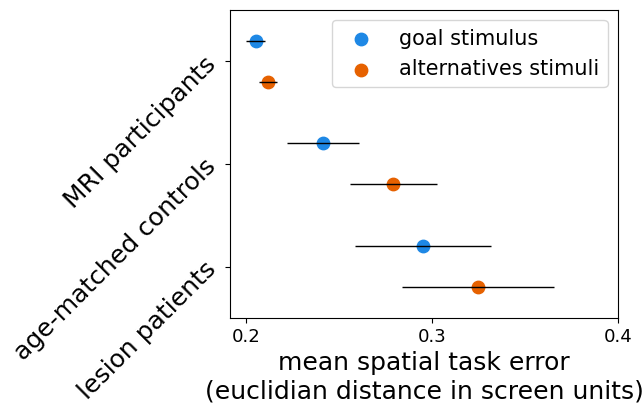

In [40]:
patient_data = all_data.loc[all_data['age_matched_control']==0,:]
EC_data =  all_data.loc[all_data['age_matched_control']==1,:]

# plot error by item status in each group

val_type_colours = ["#1E88E5", "#E66100"]

nEC = len(EC_data['participant'].unique())
EC_mean_err = np.empty((4, nEC))
for idx,p in enumerate(EC_data['participant'].unique()):
    alt_err = EC_data.loc[EC_data['participant']==p,['prevBA_err','prevWA_err']].to_numpy().flatten()
    goal_err = EC_data.loc[EC_data['participant']==p,['netitem_err']].to_numpy().flatten()
    
    EC_mean_err[0,idx] = np.nanmean(alt_err)
    EC_mean_err[1,idx] = np.nanmean(goal_err)
    EC_mean_err[2,idx]  = np.nanmean(alt_err) - np.nanmean(goal_err)
    EC_mean_err[3,idx] = np.nanmean(np.concatenate((alt_err, goal_err)).flatten())

nPatient = len(patient_data['participant'].unique())
patient_mean_error = np.empty((4,nPatient))
for idx,p in enumerate(patient_data['participant'].unique()):
    alt_err = patient_data.loc[patient_data['participant']==p,['prevBA_err','prevWA_err']].to_numpy().flatten()
    goal_err = patient_data.loc[patient_data['participant']==p,['netitem_err']].to_numpy().flatten()
    
    patient_mean_error[0,idx] = np.nanmean(alt_err)
    patient_mean_error[1,idx] = np.nanmean(goal_err) 
    patient_mean_error[2,idx] = np.nanmean(alt_err) - np.nanmean(goal_err)
    patient_mean_error[3,idx] = np.nanmean(np.concatenate((alt_err, goal_err)).flatten())


nMRI = len(df_postScanner['participant'].unique())
mri_mean_error = np.empty((4,nMRI))
for idx,p in enumerate(df_postScanner['participant'].unique()):
    alt_err = df_postScanner.loc[df_postScanner['participant']==p,['prevBA_err','prevWA_err']].to_numpy().flatten()
    goal_err = df_postScanner.loc[df_postScanner['participant']==p,['netitem_err']].to_numpy().flatten()
    
    mri_mean_error[0,idx] = np.nanmean(alt_err)
    mri_mean_error[1,idx] = np.nanmean(goal_err) 
    mri_mean_error[2,idx] = np.nanmean(alt_err) - np.nanmean(goal_err)
    mri_mean_error[3,idx] = np.nanmean(np.concatenate((alt_err, goal_err)).flatten())

    
fig,ax=plt.subplots(figsize=[5,4])
ax.errorbar([np.mean(patient_mean_error[0,:]),np.mean(patient_mean_error[1,:]),np.mean(EC_mean_err[0,:]),np.mean(EC_mean_err[1,:]),np.mean(mri_mean_error[0,:]),np.mean(mri_mean_error[1,:])],[-0.2,0.2,0.8,1.2,1.8,2.2],[0,0,0,0,0,0],[np.std(patient_mean_error[0,:])/np.sqrt(nPatient),np.std(patient_mean_error[1,:])/np.sqrt(nPatient),np.std(EC_mean_err[0,:])/np.sqrt(nEC),np.std(EC_mean_err[1,:])/np.sqrt(nEC),np.std(mri_mean_error[0,:])/np.sqrt(nMRI),np.std(mri_mean_error[1,:])/np.sqrt(nMRI)],linestyle='None',linewidth=1,color='k')

ax.scatter([np.mean(patient_mean_error[1,:]),np.mean(EC_mean_err[1,:]),np.mean(mri_mean_error[1,:])],[0.2,1.2,2.2],color=val_type_colours[0],s=80,label='goal stimulus')
ax.scatter([np.mean(patient_mean_error[0,:]),np.mean(EC_mean_err[0,:]),np.mean(mri_mean_error[0,:])],[-0.2,0.8,1.8],color=val_type_colours[1],s=80,label='alternatives stimuli')

ax.set_yticks([0,1,2], ['lesion patients','age-matched controls', 'MRI participants'],fontsize=medium_label_fontsize,rotation=45)  # Set text labels.
ax.set_ylim([-0.5,2.5])
ax.set_xticks([0.2,0.3,0.4],['0.2','0.3','0.4'],fontsize=13)
ax.set_xlabel('mean spatial task error\n(euclidian distance in screen units)',fontsize=medium_label_fontsize)
ax.legend(fontsize=small_label_fontsize)

fig.savefig(plot_folder+'patients_spatial_compare.png',bbox_inches='tight',dpi=300)